# Student Academic Performance Prediction

Compare Logistic Regression and KNN for predicting student performance
categories using the Student Performance Factors dataset.

## 1. Load and inspect the dataset

In [1]:
from pathlib import Path
import pandas as pd

# Support execution from either the project root or notebooks folder.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT / "data" / "raw" / "StudentPerformanceFactors.csv"
)

df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
df.head()

Rows: 6,607
Columns: 20


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
print("Dataset dimensions:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head(5))

print("\nLast five rows:")
display(df.tail(5))

# Includes numeric and categorical summaries.
display(df.describe(include="all").T)

Dataset dimensions: (6607, 20)

Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

First five rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70



Last five rows:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [4]:
quality_checks = pd.Series({
    "Attendance outside 0–100":
        (~df["Attendance"].between(0, 100)).sum(),

    "Previous score outside assumed 0–100":
        (~df["Previous_Scores"].between(0, 100)).sum(),

    "Exam score outside assumed 0–100":
        (~df["Exam_Score"].between(0, 100)).sum(),

    "Weekly study hours outside 0–168":
        (~df["Hours_Studied"].between(0, 168)).sum(),

    "Daily sleep hours outside 0–24":
        (~df["Sleep_Hours"].between(0, 24)).sum(),

    "Negative tutoring-session counts":
        (df["Tutoring_Sessions"] < 0).sum(),

    "Non-integer tutoring-session counts":
        (df["Tutoring_Sessions"].dropna() % 1 != 0).sum(),

    "Unexpected non-missing resource categories":
        (
            df["Access_to_Resources"].notna()
            & ~df["Access_to_Resources"].isin(["Low", "Medium", "High"])
        ).sum(),
})

display(quality_checks.to_frame("flagged_rows"))

,flagged_rows
Attendance outside 0–100,0
Previous score outside assumed 0–100,0
Exam score outside assumed 0–100,1
Weekly study hours outside 0–168,0
Daily sleep hours outside 0–24,0
Negative tutoring-session counts,0
Non-integer tutoring-session counts,0
Unexpected non-missing resource categories,0


### Validation findings

The range and category checks flagged one row with Exam_Score = 101.
This row was excluded from the modeling dataset under the documented
0–100 score-range assumption.

In [5]:
inspection = pd.DataFrame({
    "data_type": df.dtypes,
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100).round(2),
    "unique_values": df.nunique()
})

display(inspection)
print("Duplicate rows:", df.duplicated().sum())

,data_type,missing_count,missing_percent,unique_values
Hours_Studied,int64,0,0.00,41
Attendance,int64,0,0.00,41
Parental_Involvement,str,0,0.00,3
Access_to_Resources,str,0,0.00,3
Extracurricular_Activities,str,0,0.00,2
Sleep_Hours,int64,0,0.00,7
Previous_Scores,int64,0,0.00,51
Motivation_Level,str,0,0.00,3
Internet_Access,str,0,0.00,2
Tutoring_Sessions,int64,0,0.00,9


Duplicate rows: 0


In [6]:
display(df["Exam_Score"].describe())

print("Missing exam scores:", df["Exam_Score"].isna().sum())
print(
    "Scores outside 0-100:",
    ((df["Exam_Score"] < 0) | (df["Exam_Score"] > 100)).sum()
)

count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

Missing exam scores: 0
Scores outside 0-100: 1


## 2. Feature selection and target definition

The original dataset contains 20 columns. For this demonstration,
four input features are selected to match the assessment's suggested
study-related and academic indicators:

- Hours_Studied
- Attendance
- Previous_Scores
- Sleep_Hours
- Tutoring_Sessions
- Access_to_Resources

Hours_Studied is recorded per week, whereas the assessment suggests
daily study hours. The original weekly unit is retained and documented.

Assignments completed is unavailable and is therefore omitted.

Exam_Score will be used only to derive the Pass/Fail target and will
not be included as an input feature.

The proposed demonstration rule is Pass for Exam_Score >= 70 and
Fail otherwise. This is a project assumption, not an official passing
rule supplied with the dataset.

Missing values occur in three excluded columns. The four selected
inputs and Exam_Score have no missing values in the initial inspection.

One Exam_Score value exceeds the assumed 0–100 range; its handling
will be documented before modeling.

### Additional features and reasons for inclusion

Two additional features were selected alongside the four fields that
closely match the assessment's suggestions:

| Feature | Reason for inclusion |
|---------|----------------------|
| Tutoring_Sessions | Represents additional academic support received through tutoring, which may be associated with exam performance. |
| Access_to_Resources | Represents access to learning resources, which may influence a student's opportunities to study and prepare for exams. |

These are separate input features, not substitutes for the unavailable
assignments_completed field. Their inclusion does not guarantee better
predictions or establish a causal relationship with exam performance.

In [7]:
FEATURE_COLUMNS = [
    "Hours_Studied",
    "Attendance",
    "Previous_Scores",
    "Sleep_Hours",
    "Tutoring_Sessions",
    "Access_to_Resources",
]

display(df[FEATURE_COLUMNS].describe().T)

print("Missing values in selected inputs:")
print(df[FEATURE_COLUMNS].isna().sum())




,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Previous_Scores,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Sleep_Hours,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
Tutoring_Sessions,6607.0,1.493719,1.230570,0.0,1.0,1.0,2.0,8.0


Missing values in selected inputs:
Hours_Studied          0
Attendance             0
Previous_Scores        0
Sleep_Hours            0
Tutoring_Sessions      0
Access_to_Resources    0
dtype: int64


In [8]:
PASS_THRESHOLD = 70

proposed_result = df["Exam_Score"].ge(PASS_THRESHOLD).map({
    True: "Pass",
    False: "Fail",
})

# Show the number and percentage of each class.
class_summary = pd.DataFrame({
    "count": proposed_result.value_counts(),
    "percentage": (
        proposed_result.value_counts(normalize=True) * 100
    ).round(2),
})

print(f"\nProposed class distribution (threshold: {PASS_THRESHOLD}):")
display(class_summary)

# Inspect the row whose exam score is outside the assumed range.
print("\nRows with exam scores outside 0-100:")
display(df.loc[~df["Exam_Score"].between(0, 100)])


Proposed class distribution (threshold: 70):


,count,percentage
Exam_Score,,
Fail,4982,75.4
Pass,1625,24.6



Rows with exam scores outside 0-100:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


In [9]:
print("Access_to_Resources categories:")
print(df["Access_to_Resources"].value_counts(dropna=False))

Access_to_Resources categories:
Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64


### Data-quality summary and preprocessing decisions

- The original dataset contains 6,607 rows and 20 columns.
- No exact duplicate rows were found, so no duplicate rows were removed.
- Missing values were found in Teacher_Quality (78),
  Parental_Education_Level (90), and Distance_from_Home (67).
- These three columns are outside the selected six-feature scope.
  Rows were not removed because of missing values in these unused columns.
- The six selected inputs and Exam_Score have no missing values in
  the initial inspection, so missing-value imputation is not currently
  necessary for the modeling dataset.
- One row has Exam_Score = 101. Under the documented assumption that
  scores range from 0 to 100, this row is excluded from modeling.
  Its correct score cannot be verified, so it is not replaced with 100.
- The original dataframe is preserved. Reproducible filtering creates
  a separate modeling dataframe containing 6,606 rows.
- Additional checks flag invalid input ranges and unexpected categories.
  Flagged values require review before any further cleaning.
- Exam_Score is used only to derive the target. Neither Exam_Score nor
  final_result is included in the input features.
- Scaling and categorical encoding will be performed inside the model
  pipelines and fitted only on training data.

## 3. Prepare the modeling dataset

Six input features are selected. They contain no missing values in the
initial inspection. No exact duplicate rows were found in the source data.

One row has Exam_Score = 101. Assuming an exam-score range of 0–100,
this row is excluded from modeling because its correct score cannot
be verified. The original dataframe is preserved.

Pass/Fail labels are derived using a fixed demonstration threshold:
Pass for Exam_Score >= 70; Fail otherwise. This is a project assumption,
not an official passing rule from the dataset.

Fail is encoded as 1 (the positive class), and Pass as 0.
Exam_Score is excluded from the model inputs to prevent target leakage.

In [10]:
# Keep only rows with an exam score within the assumed valid range.
valid_score_mask = df["Exam_Score"].between(0, 100)
model_df = df.loc[
    valid_score_mask,
    FEATURE_COLUMNS + ["Exam_Score"]
].copy()
model_df.info()

<class 'pandas.DataFrame'>
Index: 6606 entries, 0 to 6606
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Hours_Studied        6606 non-null   int64
 1   Attendance           6606 non-null   int64
 2   Previous_Scores      6606 non-null   int64
 3   Sleep_Hours          6606 non-null   int64
 4   Tutoring_Sessions    6606 non-null   int64
 5   Access_to_Resources  6606 non-null   str  
 6   Exam_Score           6606 non-null   int64
dtypes: int64(6), str(1)
memory usage: 444.7 KB


In [11]:
# Fail = 1 (positive class); Pass = 0.
PASS_THRESHOLD = 70
model_df["final_result"] = (
    model_df["Exam_Score"] < PASS_THRESHOLD
).astype(int)

model_df.head(5)


,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours,Tutoring_Sessions,Access_to_Resources,Exam_Score,final_result
0,23,84,73,7,0,High,67,1
1,19,64,59,8,2,Medium,61,1
2,24,98,91,7,2,Medium,74,0
3,29,89,98,8,1,Medium,71,0
4,19,92,65,6,3,Medium,70,0


In [12]:
# Separate inputs from the target.
X = model_df[FEATURE_COLUMNS].copy()
y = model_df["final_result"].copy()

print("Rows excluded:", (~valid_score_mask).sum())
print("Input shape:", X.shape)
print("\nTarget counts:")
print(y.map({1: "Fail", 0: "Pass"}).value_counts())

Rows excluded: 1
Input shape: (6606, 6)

Target counts:
final_result
Fail    4982
Pass    1624
Name: count, dtype: int64


In [13]:
assert "Exam_Score" not in X.columns
assert "final_result" not in X.columns
assert X.columns.tolist() == FEATURE_COLUMNS
assert X.index.equals(y.index)
assert set(y.unique()) == {0, 1}

print("Confirmed: inputs and target are separated and aligned.")
print("\nMissing values in model inputs:")
print(X.isna().sum())

Confirmed: inputs and target are separated and aligned.

Missing values in model inputs:
Hours_Studied          0
Attendance             0
Previous_Scores        0
Sleep_Hours            0
Tutoring_Sessions      0
Access_to_Resources    0
dtype: int64


## 4. Train/test split and validation strategy

The modeling dataset is split into 80% training data and 20% held-out
test data.

- test_size=0.20: reserves 20% for final evaluation.
- random_state=42: makes the split reproducible when the dataset and
  row order remain unchanged.
- stratify=y:  preserves approximately the same Pass/Fail proportions
  in both sets, which is important because the classes are imbalanced.

### Validation and model selection

A separate fixed validation set is not used. Instead, five-fold
stratified cross-validation will be performed within the training set.

In each fold, the pipeline is fitted on four portions and evaluated on
the remaining portion. Each portion serves as validation data once.
Stratification approximately preserves class proportions in each fold.

Logistic Regression and KNN will be compared using the same folds.
Any hyperparameter tuning will use only training-set cross-validation.

Scaling and categorical encoding will be included inside each pipeline
so that preprocessing is fitted only on the training portion of each
fold.

### Evaluation criteria

Fail is encoded as 1 and treated as the positive class. Model selection
will primarily consider cross-validation macro F1, which gives both
classes equal weight. Fail-class recall and precision will also be
reviewed because missed support needs and unnecessary alerts both matter.

The selected configuration will be refitted on the full training set.
Both required classifiers will be evaluated on the held-out test set
using accuracy, precision, recall, F1-score, and confusion matrices.

Test results will be reported without using them to tune the models
or revise feature selection. The test set remains separate from
detailed exploratory analysis and model selection.

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5284, 6)
Testing shape: (1322, 6)


## 5. Exploratory Data Analysis

EDA is performed on the training set. The held-out test set is reserved
for final evaluation.

We examine:
1. Summary statistics and missing values in the selected inputs.
2. Pass/Fail class distribution.
3. Numeric feature and exam-score distributions.
4. Numeric features by Pass/Fail result, including study hours.
5. Potential outliers.
6. Result proportions and exam scores by resource access.
7. Correlations and feature–score relationships.

Pass/Fail labels use the threshold of 70. Fail is encoded as 1 and Pass as 0.

Exam_Score is included only for exploratory visualization and remains
excluded from the model inputs. Observed relationships do not establish
causation.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

numeric_features = [
    "Hours_Studied",
    "Attendance",
    "Previous_Scores",
    "Sleep_Hours",
    "Tutoring_Sessions",
]

categorical_features = ["Access_to_Resources"]
score_column = "Exam_Score"

feature_labels = {
    "Hours_Studied": "Study hours per week",
    "Attendance": "Attendance (%)",
    "Previous_Scores": "Previous exam score",
    "Sleep_Hours": "Sleep hours per night",
    "Tutoring_Sessions": "Number of tutoring sessions",
    "Exam_Score": "Final exam score",
}

RESULT_ORDER = ["Fail", "Pass"]
RESOURCE_ORDER = ["Low", "Medium", "High"]
RESULT_COLORS = {"Fail": "#e9967a", "Pass": "#4682b4"}


In [16]:
# Create a separate dataframe using training rows only.
eda_df = X_train.copy()

# Align the source scores and labels by their original row indices.
eda_df[score_column] = model_df.loc[X_train.index, score_column]
eda_df["Result"] = y_train.map({1: "Fail", 0: "Pass"})

assert eda_df["Result"].notna().all()

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Training rows used for EDA:", len(eda_df))

Training rows used for EDA: 5284


In [17]:
#Summary statistics and missing values
print("Numeric summary:")
display(eda_df[numeric_features + [score_column]].describe().T)

print("Missing values in selected inputs:")
display(
    eda_df[FEATURE_COLUMNS]
    .isna()
    .sum()
    .to_frame("missing_count")
)

resource_counts = (
    eda_df["Access_to_Resources"]
    .value_counts()
    .reindex(RESOURCE_ORDER, fill_value=0)
)

resource_summary = pd.DataFrame({
    "count": resource_counts,
    "percentage": (resource_counts / len(eda_df) * 100).round(2),
})

print("Resource-access distribution:")
display(resource_summary)

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Hours_Studied,5284.0,19.975776,6.017686,1.0,16.00,20.0,24.00,44.0
Attendance,5284.0,80.029145,11.492828,60.0,70.00,80.0,90.00,100.0
Previous_Scores,5284.0,74.878312,14.446549,50.0,62.75,75.0,87.25,100.0
Sleep_Hours,5284.0,7.031983,1.466749,4.0,6.00,7.0,8.00,10.0
Tutoring_Sessions,5284.0,1.506624,1.234310,0.0,1.00,1.0,2.00,8.0
Exam_Score,5284.0,67.234860,3.863601,57.0,65.00,67.0,69.00,100.0


Missing values in selected inputs:


,missing_count
Hours_Studied,0
Attendance,0
Previous_Scores,0
Sleep_Hours,0
Tutoring_Sessions,0
Access_to_Resources,0


Resource-access distribution:


,count,percentage
Access_to_Resources,,
Low,1087,20.57
Medium,2632,49.81
High,1565,29.62


,count,percentage
Result,,
Fail,3985,75.42
Pass,1299,24.58


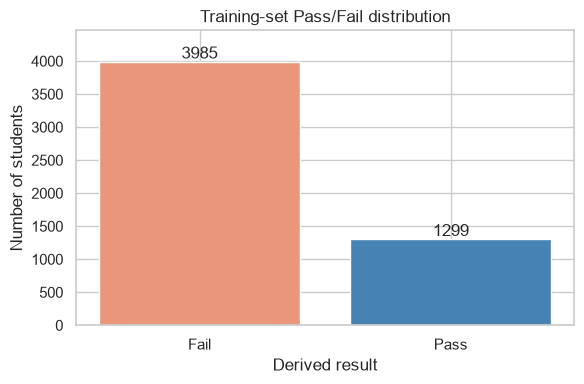

In [18]:
#Pass/Fail class distribution
class_counts = (
    eda_df["Result"]
    .value_counts()
    .reindex(RESULT_ORDER, fill_value=0)
)

class_summary = pd.DataFrame({
    "count": class_counts,
    "percentage": (class_counts / len(eda_df) * 100).round(2),
})

display(class_summary)

fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(
    class_counts.index,
    class_counts.values,
    color=[RESULT_COLORS[label] for label in class_counts.index],
)

ax.set_title("Training-set Pass/Fail distribution")
ax.set_xlabel("Derived result")
ax.set_ylabel("Number of students")
ax.bar_label(ax.containers[0])
ax.margins(y=0.12)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_class_distribution.png", dpi=150)
plt.show()

**Class imbalance:** The training set contains 3,985 Fail labels and
   1,299 Pass labels, approximately 75.4% and 24.6%, respectively.
   Always predicting Fail would achieve approximately 75.4% training
   accuracy while failing to identify any Pass cases. Accuracy alone
   is therefore insufficient.

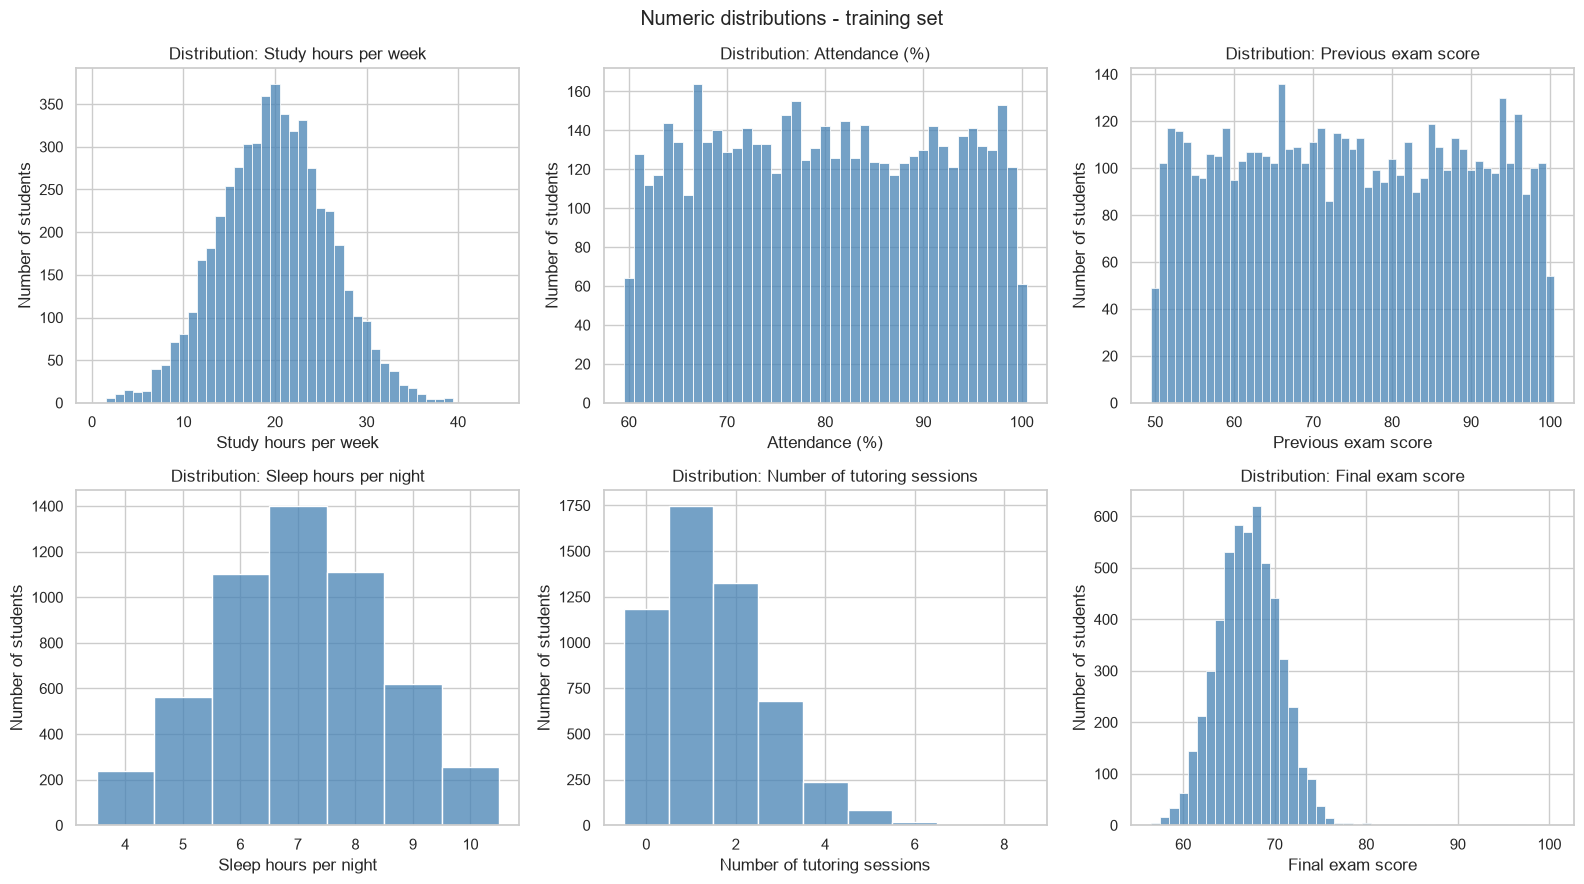

In [19]:
#Numeric distributions
distribution_columns = numeric_features + [score_column]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, column in zip(axes.flat, distribution_columns):
    sns.histplot(
        data=eda_df,
        x=column,
        discrete=True,
        color="steelblue",
        ax=ax,
    )

    ax.set_title(f"Distribution: {feature_labels[column]}")
    ax.set_xlabel(feature_labels[column])
    ax.set_ylabel("Number of students")

fig.suptitle("Numeric distributions - training set")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_numeric_distributions.png", dpi=150)
plt.show()

1. **Study hours per week:** The distribution is approximately
   bell-shaped and centred around 20 hours per week. Most observations
   lie roughly between 10 and 30 hours, with relatively few students
   reporting very low or very high study hours.

2. **Attendance:** Attendance is spread relatively evenly between
   60% and 100%, with no single dominant peak. No values below 60%
   appear in this training sample, so performance for students with
   lower attendance cannot be established from these data.

3. **Previous exam score:** Previous scores are distributed fairly
   evenly between 50 and 100. This provides a broad range of prior
   performance, although scores below 50 are not represented.

4. **Sleep hours per night:** Sleep duration is concentrated around
   seven hours, with six to eight hours being common. Values near
   four and ten hours occur less frequently. This plot describes
   sleep patterns but does not show their relationship with Pass/Fail.

5. **Tutoring sessions:** The distribution is right-skewed. One session
   is the most frequent value, and most observations fall between
   zero and three sessions. Higher counts are uncommon, but rarity
   alone does not make them invalid.

6. **Final exam score:** Scores are tightly concentrated around the
   mid-to-high 60s, with a peak near 67–68 and a sparse right tail.
   The assumed passing threshold of 70 lies above the main peak,
   helping explain why Fail is the majority derived class.

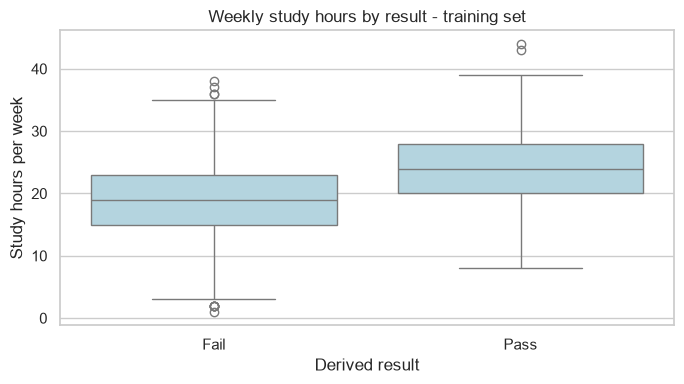

In [20]:
#Study hours by Pass/Fail
fig, ax = plt.subplots(figsize=(7, 4))

sns.boxplot(
    data=eda_df,
    x="Result",
    y="Hours_Studied",
    order=RESULT_ORDER,
    color="lightblue",
    ax=ax,
)

ax.set_title("Weekly study hours by result - training set")
ax.set_xlabel("Derived result")
ax.set_ylabel("Study hours per week")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_study_hours_by_result.png", dpi=150)
plt.show()

**Study hours:** Median weekly study time is approximately 24 hours
   in the Pass group and 19 hours in the Fail group. The distributions
   overlap, so study hours alone do not perfectly separate the classes.

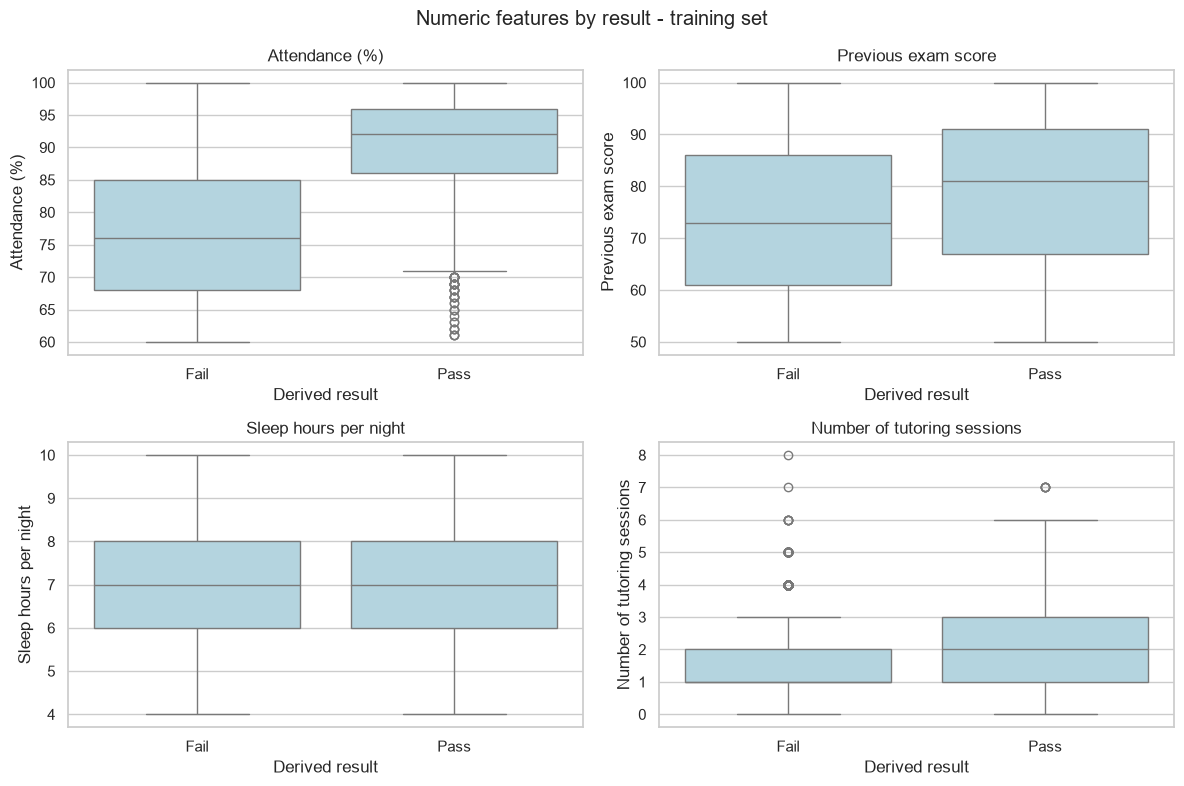

Numeric feature medians by result:


Result,Fail,Pass
Hours_Studied,19.0,24.0
Attendance,76.0,92.0
Previous_Scores,73.0,81.0
Sleep_Hours,7.0,7.0
Tutoring_Sessions,1.0,2.0


In [21]:
#Other numeric features by Pass/Fail
other_numeric_features = [
    "Attendance",
    "Previous_Scores",
    "Sleep_Hours",
    "Tutoring_Sessions",
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.flat, other_numeric_features):
    sns.boxplot(
        data=eda_df,
        x="Result",
        y=column,
        order=RESULT_ORDER,
        color="lightblue",
        ax=ax,
    )

    ax.set_title(feature_labels[column])
    ax.set_xlabel("Derived result")
    ax.set_ylabel(feature_labels[column])

fig.suptitle("Numeric features by result - training set")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_features_by_result.png", dpi=150)
plt.show()

# Exact medians to support written observations.
print("Numeric feature medians by result:")
display(
    eda_df.groupby("Result")[numeric_features]
    .median()
    .reindex(RESULT_ORDER)
    .T
)

**Attendance:** Median attendance is approximately 92% in the Pass
   group and 76% in the Fail group. Higher attendance is associated
   with the derived Pass label in this training sample.

**Previous scores and tutoring:** The Pass group has higher median
   previous scores and tutoring-session counts than the Fail group.
   These differences do not establish causal effects.

**Sleep:** Both classes have a median of approximately seven hours
   of sleep, with similar boxplots. This does not prove that sleep has
   no relationship with performance.

**Resource access:** The proportion labelled Pass is approximately
   15% for Low, 24% for Medium, and 34% for High resource access.
   These percentages compare results within each resource group.

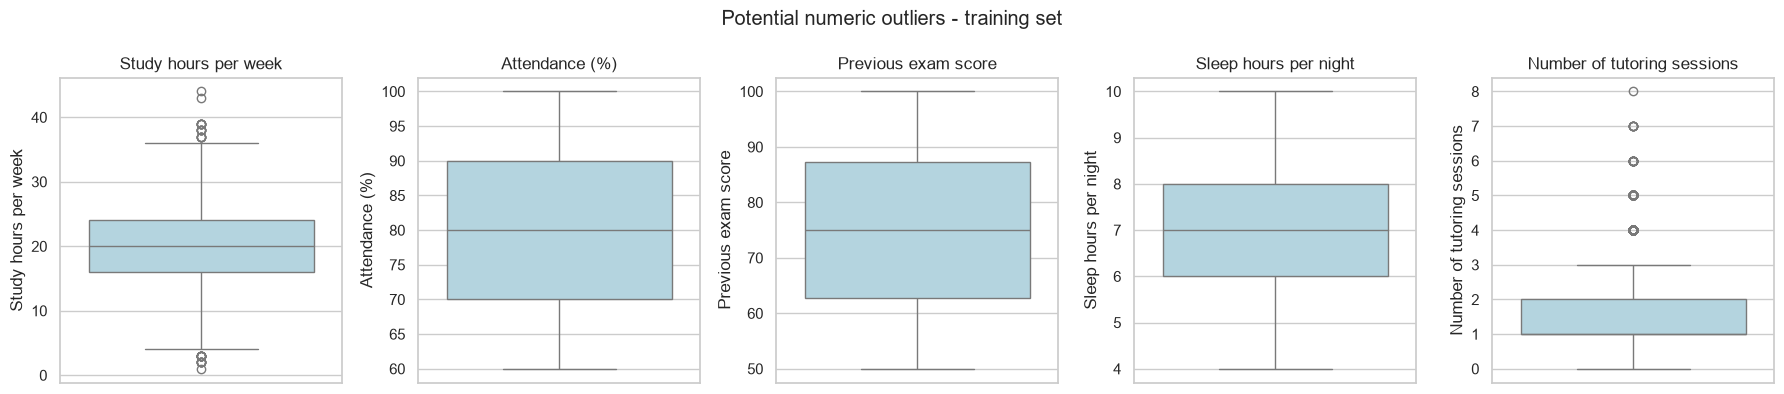

In [22]:
#Potential outliers
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, column in zip(axes, numeric_features):
    sns.boxplot(
        data=eda_df,
        y=column,
        color="lightblue",
        ax=ax,
    )

    ax.set_title(feature_labels[column])
    ax.set_ylabel(feature_labels[column])

fig.suptitle("Potential numeric outliers - training set")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_outlier_boxplots.png", dpi=150)
plt.show()

1. **Study hours:** A few observations with very low weekly study hours
   (approximately 1–3) and high weekly study hours (above approximately
   35) appear beyond the whiskers. These values are unusual relative
   to the training sample but are not necessarily incorrect.

2. **Attendance:** Values extend from approximately 60% to 100%, with
   no points flagged beyond the whiskers. All displayed values fall
   within the valid percentage range.

3. **Previous exam scores:** Scores span approximately 50–100, with
   no points flagged beyond the whiskers. The spread indicates varied
   prior academic performance.

4. **Sleep hours:** The middle 50% of observations lie approximately
   between six and eight hours per night, with a median near seven.
   No points appear beyond the whiskers.

5. **Tutoring sessions:** Counts of approximately four to eight sessions
   appear beyond the upper whisker. This reflects the right-skewed
   distribution: most students have relatively few sessions, while
   higher counts are less common.

### Handling decision

No additional rows are removed or values capped based on these plots.
The flagged study-hour and tutoring-session values passed our basic
plausibility checks, and there is no evidence that they are recording
errors.

Boxplot outliers are defined relative to the interquartile range;
they are not automatically invalid values. Likewise, the absence of
flagged outliers does not guarantee that a column is free of errors.

Counts by resource group:


Result,Fail,Pass
Access_to_Resources,,
Low,924,163
Medium,2022,610
High,1039,526


Percentages within each resource group:


Result,Fail,Pass
Access_to_Resources,,
Low,85.00,15.00
Medium,76.82,23.18
High,66.39,33.61


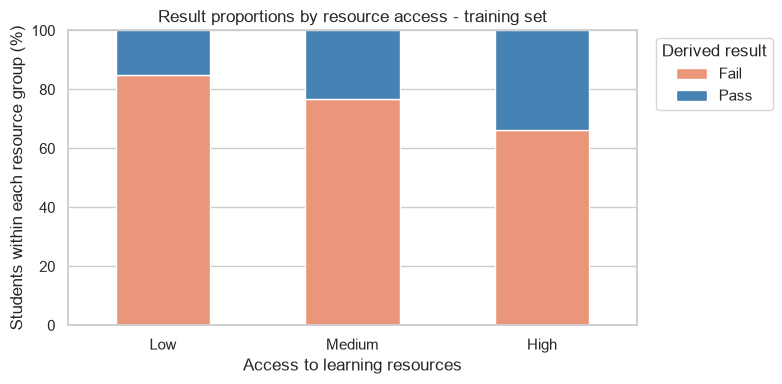

In [23]:
#Pass/Fail proportions by resource access
resource_result_counts = pd.crosstab(
    eda_df["Access_to_Resources"],
    eda_df["Result"],
).reindex(
    index=RESOURCE_ORDER,
    columns=RESULT_ORDER,
    fill_value=0,
)

resource_percentages = (
    resource_result_counts
    .div(resource_result_counts.sum(axis=1), axis=0)
    .mul(100)
)

print("Counts by resource group:")
display(resource_result_counts)

print("Percentages within each resource group:")
display(resource_percentages.round(2))

ax = resource_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4),
    color=[RESULT_COLORS[label] for label in RESULT_ORDER],
)

ax.set_title("Result proportions by resource access - training set")
ax.set_xlabel("Access to learning resources")
ax.set_ylabel("Students within each resource group (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Derived result",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
)

fig = ax.get_figure()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_resource_result_proportions.png", dpi=150)
plt.show()

**Resource access:** The proportion labelled Pass increases from
   approximately 15% for Low resource access to 24% for Medium and 34%
   for High. These are within-group percentages, not raw student counts.
   Other factors may contribute to the observed differences.

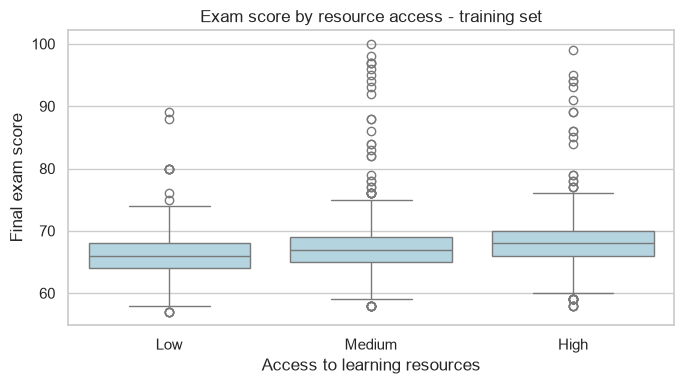

In [24]:
#Resource access versus exam score
fig, ax = plt.subplots(figsize=(7, 4))

sns.boxplot(
    data=eda_df,
    x="Access_to_Resources",
    y=score_column,
    order=RESOURCE_ORDER,
    color="lightblue",
    ax=ax,
)

ax.set_title("Exam score by resource access - training set")
ax.set_xlabel("Access to learning resources")
ax.set_ylabel("Final exam score")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_resources_exam_score.png", dpi=150)
plt.show()

- Median exam scores increase slightly with resource access:
  approximately 66 for Low, 67 for Medium, and 68 for High.

- The middle 50% of scores lie approximately between 64–68 for Low,
  65-69 for Medium, and 66-70 for High resource access.

- The distributions overlap substantially. Resource access alone
  therefore does not clearly separate students by exam performance.

- All three groups contain unusually high scores relative to their
  group distributions. These points are not automatically errors;
  they remain within the assumed valid score range of 0-100.

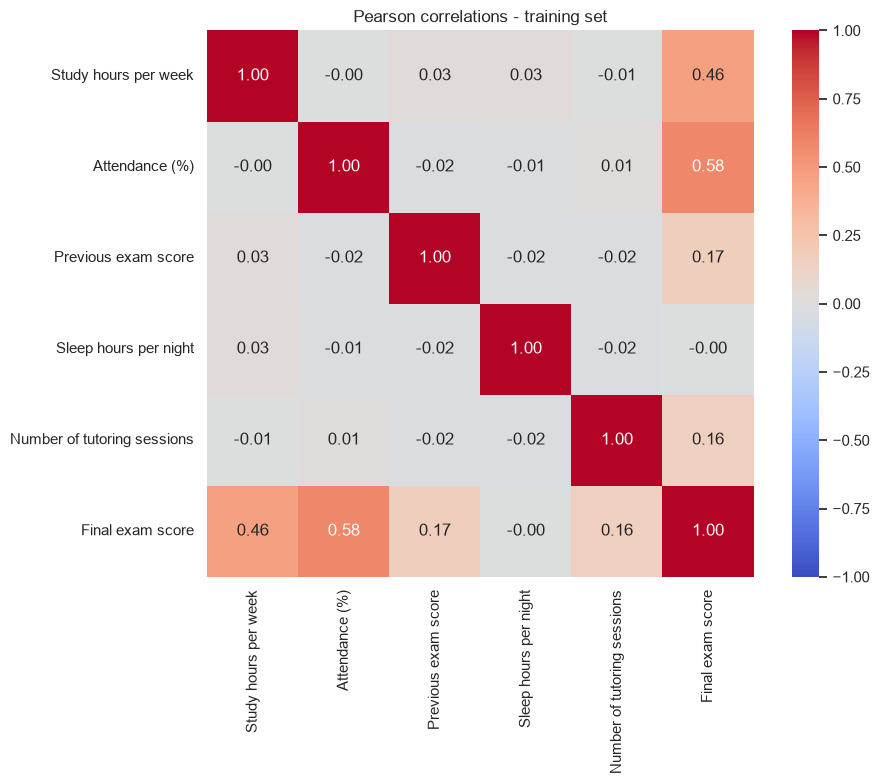

In [26]:
#Correlation heatmap
correlation = eda_df[numeric_features + [score_column]].corr(
    method="pearson"
)

readable_correlation = correlation.rename(
    index=feature_labels,
    columns=feature_labels,
)

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    readable_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)

ax.set_title("Pearson correlations - training set")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "08_correlations.png", dpi=150)
plt.show()

1. **Attendance:** Attendance has the strongest positive correlation
   with final exam score among the plotted inputs (r = 0.58).
   Higher attendance tends to accompany higher exam scores in this
   training sample.

2. **Study hours:** Weekly study hours have a moderate positive
   correlation with exam score (r = 0.46). Students who study more
   hours tend to have higher scores, although the relationship
   is not perfect.

3. **Previous scores and tutoring:** Previous exam scores (r = 0.17)
   and tutoring-session counts (r = 0.16) have weak positive linear
   relationships with final exam score.

4. **Sleep hours:** The correlation with exam score is approximately
   zero. This indicates little linear association in this sample,
   but does not rule out nonlinear relationships or interactions
   with other features. The displayed -0.00 is a rounded value.

5. **Relationships between inputs:** Pairwise correlations among the
   five numeric inputs are close to zero, ranging approximately
   from -0.02 to 0.03. There is no evidence of strong pairwise linear
   correlation among these inputs.

Attendance and study hours show the clearest individual linear
associations with exam score. However, these correlations are not
model feature-importance scores and do not establish causation.

Weak correlation alone is not a sufficient reason to remove a feature.
Predictive usefulness will be assessed through training-set
cross-validation.

The heatmap concerns the continuous Exam_Score, whereas our models
predict derived Pass/Fail labels. Exam_Score remains excluded from
model inputs to prevent target leakage.

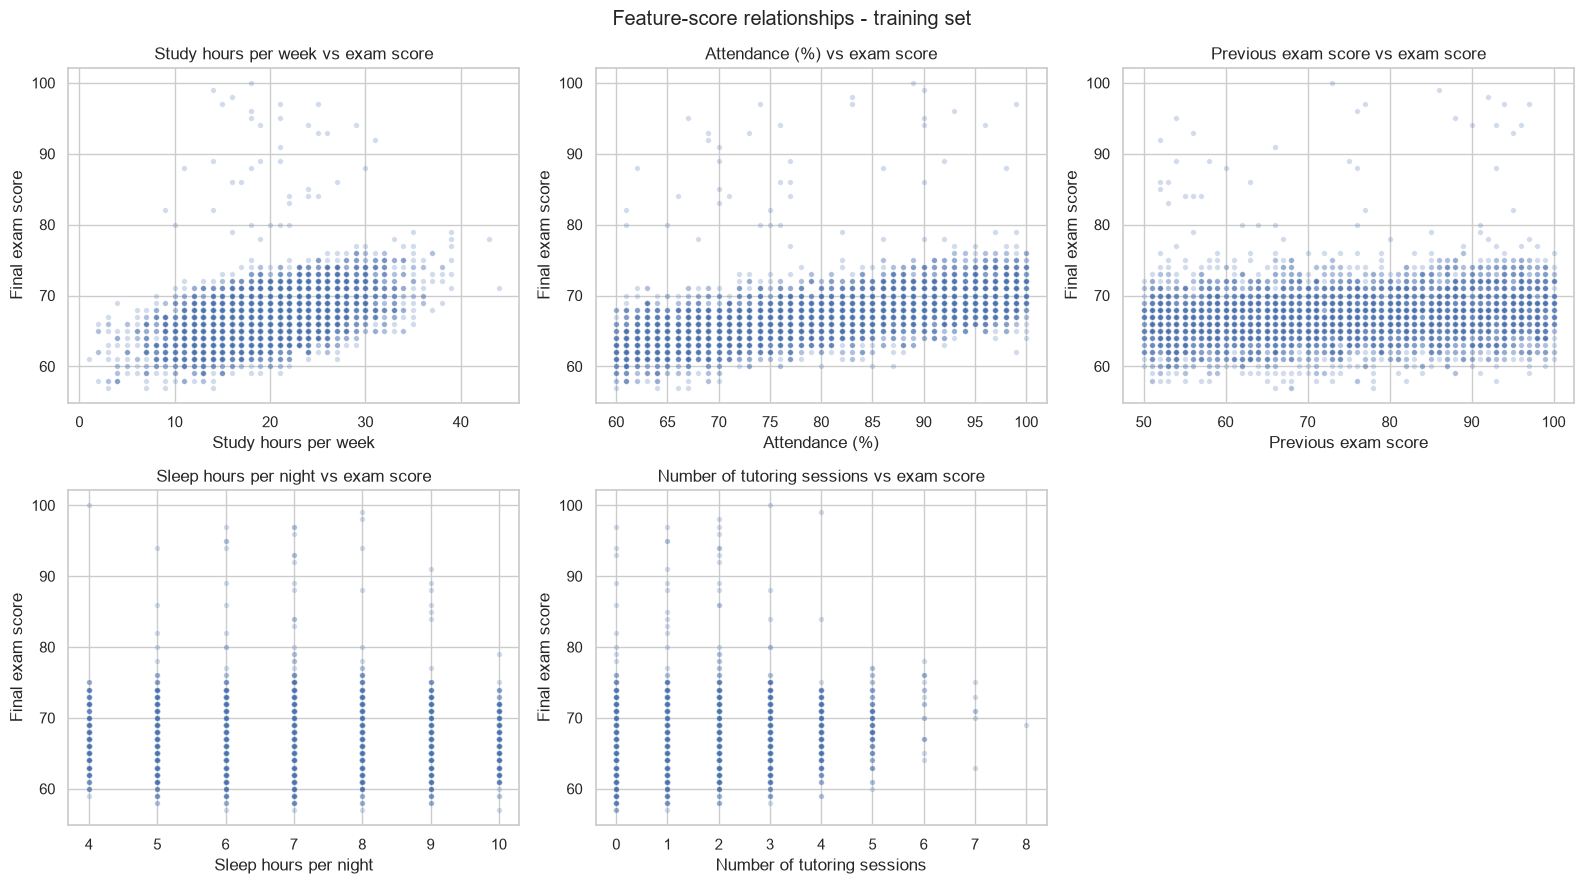

In [25]:
#Numeric features versus exam score
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, column in zip(axes.flat, numeric_features):
    sns.scatterplot(
        data=eda_df,
        x=column,
        y=score_column,
        alpha=0.25,
        s=15,
        ax=ax,
    )

    ax.set_title(f"{feature_labels[column]} vs exam score")
    ax.set_xlabel(feature_labels[column])
    ax.set_ylabel("Final exam score")

# Only five features are plotted.
axes.flat[-1].set_visible(False)

fig.suptitle("Feature-score relationships - training set")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_feature_score_scatterplots.png", dpi=150)
plt.show()

1. **Study hours:** The main cluster shows an upward trend: higher
   weekly study hours generally accompany higher exam scores.
   However, scores vary among students with similar study hours,
   so study time alone cannot fully explain performance.

2. **Attendance:** Exam scores tend to increase with attendance.
   The pattern is consistent with the positive correlation observed
   in the heatmap (r = 0.58), although substantial variation remains
   at each attendance level.

3. **Previous exam scores:** A slight positive trend is visible,
   but final scores overlap considerably across the previous-score
   range. This agrees with the weak positive correlation (r = 0.17).

4. **Sleep hours:** No clear upward or downward trend is visible.
   Similar score ranges occur across several sleep durations.
   The vertical bands appear because sleep hours are recorded
   as whole-number values.

5. **Tutoring sessions:** There is a weak positive association with
   exam score, consistent with the heatmap (r = 0.16). High session
   counts have relatively few observations, so patterns at those
   counts should be interpreted cautiously. Vertical bands reflect
   the discrete session counts.
   
Study hours and attendance show clearer positive trends than the
other numeric inputs. Nevertheless, none of the individual features
perfectly explains exam scores.

## 6. Preprocessing and model pipelines

Five numeric inputs are standardized using StandardScaler:
Hours_Studied, Attendance, Previous_Scores, Sleep_Hours,
and Tutoring_Sessions.

Access_to_Resources is converted into binary indicator columns using
one-hot encoding. This avoids assuming equal numerical gaps between
Low, Medium, and High resource access.

The selected inputs contain no missing values, so imputation is not
required for this dataset.

### Why scaling is needed

KNN uses distances between observations. Without scaling, features
with larger numerical spreads can dominate these distances.

Standardization also helps the optimization and regularization of
Logistic Regression. Numeric features are centred and scaled using
statistics learned only from the relevant training data.

### Models

- Logistic Regression learns a weighted combination of the processed
  inputs and converts it into an estimated probability of Fail.
  It provides a simple linear classification baseline.

- KNN classifies a student using the labels of nearby training
  observations. We begin with five neighbours and equal voting weights.
  It can capture local patterns without assuming a linear boundary.

Each model has its own preprocessing pipeline. During cross-validation,
preprocessing and model fitting occur within each training fold.
The held-out test set is not used at this stage.

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

In [29]:
numeric_features = [
    "Hours_Studied",
    "Attendance",
    "Previous_Scores",
    "Sleep_Hours",
    "Tutoring_Sessions",
]

categorical_features = ["Access_to_Resources"]

In [30]:
def create_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                numeric_features,
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
                categorical_features,
            ),
        ],
        remainder="drop",
    )

In [31]:
#pipelines
models = {
    "Logistic Regression": Pipeline(
        steps=[
            ("preprocessing", create_preprocessor()),
            (
                "classifier",
                LogisticRegression(
                    max_iter=1000,
                    random_state=42,
                ),
            ),
        ]
    ),

    "KNN": Pipeline(
        steps=[
            ("preprocessing", create_preprocessor()),
            (
                "classifier",
                KNeighborsClassifier(
                    n_neighbors=5,
                    weights="uniform",
                ),
            ),
        ]
    ),
}

for name, pipeline in models.items():
    print(f"\n{name}")
    display(pipeline)


Logistic Regression


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float,


KNN


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float,

### How the models make predictions

#### Logistic Regression

Logistic Regression multiplies each processed input by a learned
coefficient, adds the results and an intercept, and converts that total
into a probability between 0 and 1 using the sigmoid function.

In this project, that probability estimates the likelihood of
Fail (class 1). With the default decision rule, a probability above
0.5 produces a Fail prediction; otherwise, the prediction is Pass.

The coefficients are learned from the training data. Despite its name,
Logistic Regression is a classification algorithm.

It is a reasonable baseline because it is fast, relatively easy to
interpret, and provides a simple linear decision boundary against
which we can compare other approaches.

#### K-Nearest Neighbors (KNN)

KNN stores the processed training examples and their labels.
For a new student, it calculates distances to those examples and
finds the five nearest neighbours.

Our model uses equal voting weights. If three or more of those five
neighbours are labelled Fail, it predicts Fail; otherwise, it predicts
Pass.

Numeric features are standardized so differences in measurement scales
do not dominate the distance calculation. Resource access is one-hot
encoded.

KNN is a reasonable baseline because its prediction rule is intuitive
and it can capture local, nonlinear patterns. Comparing it with Logistic
Regression lets us compare a neighbourhood-based approach with a
linear classifier.

## 7. Cross-validation comparison

Both pipelines are evaluated using the same five stratified folds
within the training set. Each fold preserves approximately the
training set's class proportions.

For each iteration, preprocessing and the classifier are fitted on
four folds and evaluated on the remaining fold.

Reported metrics:
- Accuracy
- Precision, recall, and F1-score for Fail (positive class = 1)
- Macro F1, which gives Pass and Fail equal weight

Mean macro F1 is the primary model-selection metric. Fail-class
precision and recall are also reviewed to understand the trade-off
between unnecessary alerts and missed potential support needs.

A majority-class dummy classifier is included as a reference.
No test data is used for this comparison.

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.dummy import DummyClassifier

In [33]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Store the splits so every model uses exactly the same folds.
cv_splits = list(cv.split(X_train, y_train))

scoring = {
    "accuracy": "accuracy",

    "precision_fail": make_scorer(
        precision_score,
        pos_label=1,
        zero_division=0,
    ),

    "recall_fail": make_scorer(
        recall_score,
        pos_label=1,
        zero_division=0,
    ),

    "f1_fail": make_scorer(
        f1_score,
        pos_label=1,
        zero_division=0,
    ),

    "macro_f1": make_scorer(
        f1_score,
        average="macro",
        zero_division=0,
    ),
}

In [34]:
comparison_models = {
    "Dummy (majority class)": DummyClassifier(
        strategy="most_frequent"
    ),
    **models,
}

cv_results = {}
comparison_rows = []

for name, estimator in comparison_models.items():
    scores = cross_validate(
        estimator=estimator,
        X=X_train,
        y=y_train,
        cv=cv_splits,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise",
    )

    cv_results[name] = scores

    row = {"Model": name}

    for metric in scoring:
        fold_scores = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = fold_scores.mean()
        row[f"{metric}_std"] = fold_scores.std()

    comparison_rows.append(row)

cv_summary = (
    pd.DataFrame(comparison_rows)
    .set_index("Model")
    .sort_values("macro_f1_mean", ascending=False)
)

display(cv_summary.round(4))

,accuracy_mean,accuracy_std,precision_fail_mean,precision_fail_std,recall_fail_mean,recall_fail_std,f1_fail_mean,f1_fail_std,macro_f1_mean,macro_f1_std
Model,,,,,,,,,,
Logistic Regression,0.9042,0.0036,0.9273,0.0050,0.9473,0.0066,0.9372,0.0025,0.8679,0.0051
KNN,0.8787,0.0036,0.9020,0.0071,0.9415,0.0083,0.9213,0.0024,0.8283,0.0063
Dummy (majority class),0.7542,0.0003,0.7542,0.0003,1.0000,0.0000,0.8599,0.0002,0.4299,0.0001


In [35]:
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

cv_summary.to_csv(REPORTS_DIR / "cv_model_comparison.csv")

print("Cross-validation results saved.")

Cross-validation results saved.


### Cross-validation results and model selection

Logistic Regression achieved the highest mean macro F1 (0.8679),
compared with KNN (0.8283) and the majority-class baseline (0.4299).

It also achieved higher accuracy, Fail-class precision, and Fail-class
recall than KNN. Therefore, Logistic Regression is selected as the
preferred model among the configurations evaluated.

Logistic Regression's macro F1 standard deviation was 0.0051,
compared with 0.0063 for KNN. Performance varied relatively little
across these five folds, although this does not establish performance
on external datasets.

The dummy classifier achieved 75.42% accuracy and 100% Fail recall
by predicting Fail for every observation. Its Pass-class F1 was zero,
demonstrating why accuracy and Fail recall alone are insufficient.

For this assessment, the baseline configurations are retained without
additional hyperparameter tuning. The selection is based only on
training-set cross-validation; the held-out test set has not been
used for model selection.

All labels are derived using the assumed exam-score threshold of 70.


In [36]:
# Record the selection before examining test results.
selected_model_name = "Logistic Regression"

# Cross-validation fitted temporary copies.
# Now fit the original pipelines on all training rows.
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    print(f"{name}: fitted on {len(X_train):,} training rows.")

selected_pipeline = models[selected_model_name]

Logistic Regression: fitted on 5,284 training rows.
KNN: fitted on 5,284 training rows.


### 8.Hyperparameter tuning

Both models are tuned using five-fold stratified cross-validation
on the training set only.

The search considers:
- Logistic Regression: regularization strength C.
- KNN: number of neighbours and voting weights.

Mean macro F1 is the selection metric because it gives Pass and Fail
equal weight. Preprocessing remains inside each pipeline and is fitted
separately within each training fold.

GridSearchCV automatically refits the best configuration for each model
on the complete training set. Test data is not used in this search.

In [37]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

parameter_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1.0, 10.0, 100.0],
    },
    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9, 15, 21],
        "classifier__weights": ["uniform", "distance"],
    },
}

In [38]:
tuning_searches = {}
tuned_models = {}
tuning_rows = []

for name, pipeline in models.items():
    search = GridSearchCV(
        estimator=clone(pipeline),
        param_grid=parameter_grids[name],
        scoring=scoring,
        refit="macro_f1",
        cv=cv_splits,
        n_jobs=-1,
        error_score="raise",
    )

    # Training data only.
    search.fit(X_train, y_train)

    tuning_searches[name] = search
    tuned_models[name] = search.best_estimator_

    best_index = search.best_index_

    tuning_rows.append({
        "Model": name,
        "Best parameters": str(search.best_params_),
        "CV macro F1": search.best_score_,
        "CV macro F1 std": (
            search.cv_results_["std_test_macro_f1"][best_index]
        ),
        "CV Fail precision": (
            search.cv_results_["mean_test_precision_fail"][best_index]
        ),
        "CV Fail recall": (
            search.cv_results_["mean_test_recall_fail"][best_index]
        ),
    })

    print(f"\n{name}")
    print("Best parameters:", search.best_params_)
    print(f"Best CV macro F1: {search.best_score_:.4f}")


Logistic Regression
Best parameters: {'classifier__C': 10.0}
Best CV macro F1: 0.8685

KNN
Best parameters: {'classifier__n_neighbors': 21, 'classifier__weights': 'distance'}
Best CV macro F1: 0.8413


In [39]:
tuning_summary = (
    pd.DataFrame(tuning_rows)
    .set_index("Model")
    .sort_values("CV macro F1", ascending=False)
)

tuning_summary["Baseline CV macro F1"] = cv_summary["macro_f1_mean"]

tuning_summary["CV improvement"] = (
    tuning_summary["CV macro F1"]
    - tuning_summary["Baseline CV macro F1"]
)

display(tuning_summary.round(4))

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

tuning_summary.to_csv(REPORTS_DIR / "tuning_summary.csv")

for name, search in tuning_searches.items():
    filename = name.lower().replace(" ", "_")

    pd.DataFrame(search.cv_results_).to_csv(
        REPORTS_DIR / f"{filename}_grid_search.csv",
        index=False,
    )

,Best parameters,CV macro F1,CV macro F1 std,CV Fail precision,CV Fail recall,Baseline CV macro F1,CV improvement
Model,,,,,,,
Logistic Regression,{'classifier__C': 10.0},0.8685,0.0069,0.9280,0.9471,0.8679,0.0007
KNN,"{'classifier__n_neighbors': 21, 'classifier__w...",0.8413,0.0085,0.9015,0.9598,0.8283,0.0130


### Hyperparameter-tuning results

Logistic Regression's best tested configuration used C=10.0.
This applies weaker regularization than the baseline C=1.0.

Its mean CV macro F1 increased from 0.8679 to 0.8685. This improvement
is very small relative to the fold-to-fold variation, so it should
not be interpreted as convincing evidence of a meaningful gain.

KNN's best tested configuration used 21 neighbours with distance
weighting. It considers more neighbours than the baseline, while
giving closer observations greater influence.

KNN's mean CV macro F1 increased from 0.8283 to 0.8413.
Fail recall increased from 0.9415 to 0.9598, while Fail precision
decreased slightly from 0.9020 to 0.9015.

Tuned Logistic Regression remains the preferred configuration based
on the highest mean CV macro F1 among the candidates searched.

These are the best settings within the specified grids, not necessarily
the best possible settings. The best CV scores may be optimistic because
the same folds were used to select the hyperparameters.

In [40]:
selected_model_name = tuning_summary["CV macro F1"].idxmax()
selected_pipeline = tuned_models[selected_model_name]

print("Selected model:", selected_model_name)
print(
    "Best parameters:",
    tuning_searches[selected_model_name].best_params_,
)

Selected model: Logistic Regression
Best parameters: {'classifier__C': 10.0}


## 9.Test evaluation

The tuned Logistic Regression and KNN pipelines are evaluated on the
held-out test split. Preprocessing uses parameters learned from training
data, and no fitting occurs during prediction.

Model selection was based on training-set cross-validation macro F1.

Fail = 1 is the positive class; Pass = 0 is the negative class.
We report accuracy, Fail precision, recall and F1, macro F1,
per-class metrics, and confusion matrices.

This split was evaluated during an earlier baseline experiment.
Its reuse is acknowledged; test results are not used for further tuning.

In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [42]:
#Predict and create the comparison table
tuned_test_predictions = {}
test_rows = []

for name, pipeline in tuned_models.items():
    # Applies fitted preprocessing, then predicts.
    y_pred = pipeline.predict(X_test)
    tuned_test_predictions[name] = y_pred

    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Fail)": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Recall (Fail)": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "F1 (Fail)": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
    })

tuned_test_summary = (
    pd.DataFrame(test_rows).set_index("Model")
)

display(tuned_test_summary.round(4))

tuned_test_summary.to_csv(
    REPORTS_DIR / "tuned_test_model_comparison.csv"
)

,Accuracy,Precision (Fail),Recall (Fail),F1 (Fail),Macro F1
Model,,,,,
Logistic Regression,0.9130,0.9332,0.9529,0.9429,0.8800
KNN,0.9002,0.9069,0.9669,0.9359,0.8549


### Interpretation of tuned-model metrics

Logistic Regression achieved higher accuracy, Fail precision,
Fail F1, and macro F1 than KNN.

KNN achieved higher Fail recall (96.69% versus 95.29%), meaning it
identified a larger proportion of students with the derived Fail label.
However, its lower Fail precision indicates more unnecessary alerts
among its Fail predictions.

Logistic Regression remains the selected model based on its higher
training-set cross-validation macro F1. Its test macro F1 of 0.8800
is consistent with that selection and reflects better average F1
across Pass and Fail than KNN's 0.8549.

In [43]:
#Display and save per-class reports
for name, y_pred in tuned_test_predictions.items():
    report = classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Pass", "Fail"],
        digits=4,
        zero_division=0,
    )

    print(f"\nTuned {name}")
    print(report)

    filename = name.lower().replace(" ", "_")

    (REPORTS_DIR / f"tuned_{filename}_classification_report.txt").write_text(
        report,
        encoding="utf-8",
    )


Tuned Logistic Regression
              precision    recall  f1-score   support

        Pass     0.8454    0.7908    0.8172       325
        Fail     0.9332    0.9529    0.9429       997

    accuracy                         0.9130      1322
   macro avg     0.8893    0.8718    0.8800      1322
weighted avg     0.9116    0.9130    0.9120      1322


Tuned KNN
              precision    recall  f1-score   support

        Pass     0.8726    0.6954    0.7740       325
        Fail     0.9069    0.9669    0.9359       997

    accuracy                         0.9002      1322
   macro avg     0.8897    0.8311    0.8549      1322
weighted avg     0.8984    0.9002    0.8961      1322



### Per-class classification report

The test set contains 325 Pass cases and 997 Fail cases.
The support column gives the actual number of observations in each class.

#### Tuned Logistic Regression

- Pass precision is 84.54%: among predictions of Pass, 84.54%
  match the derived Pass label.
- Pass recall is 79.08%: the model correctly identifies 257 of
  the 325 Pass cases.
- Pass F1 is 0.8172.
- Fail recall is 95.29%: the model identifies 950 of 997 Fail cases.
- Fail F1 is 0.9429.

Performance is stronger for Fail than Pass, so the overall accuracy
of 91.30% does not fully describe performance on the minority class.

#### Tuned KNN

- Pass precision is 87.26%, slightly higher than Logistic Regression.
- Pass recall is 69.54%: the model identifies only 226 of 325 Pass cases.
- Pass F1 is 0.7740.
- Fail recall is 96.69%: the model identifies 964 of 997 Fail cases.
- Fail F1 is 0.9359.

KNN's Pass predictions are more precise, but it identifies fewer
actual Pass cases. Its higher Fail recall comes with more Pass cases
incorrectly predicted as Fail.

#### Macro and weighted averages

Macro averages give Pass and Fail equal weight. Logistic Regression
has the higher macro F1: 0.8800 versus 0.8549.

Weighted averages weight each class by its support. Because Fail
accounts for approximately 75.4% of the test set, its stronger results
have greater influence on weighted F1.

The weighted F1 values—0.9120 for Logistic Regression and 0.8961 for
KNN—are therefore higher than the corresponding macro F1 values.

#### Conclusion

Logistic Regression achieves higher F1 for both classes and remains
the model selected through training-set cross-validation.

KNN achieves higher Fail recall, but Logistic Regression identifies
more Pass cases while generating fewer unnecessary Fail alerts.

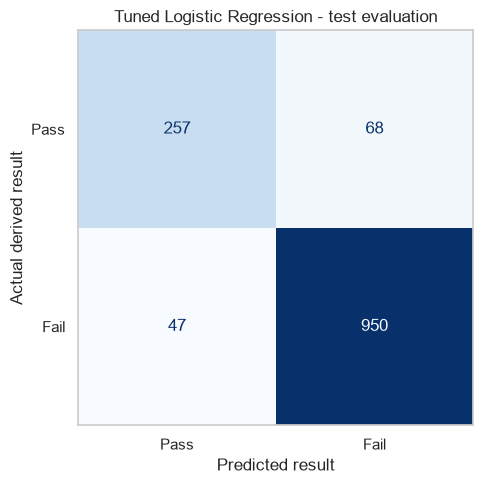

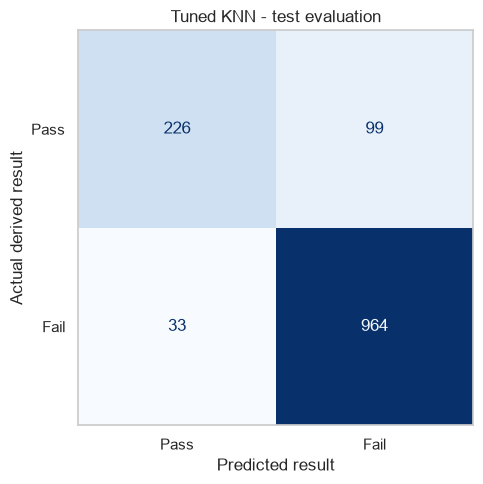

In [46]:
#Plot and save the confusion matrices
confusion_rows = []

for name, y_pred in tuned_test_predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1],
    )

    tn, fp, fn, tp = cm.ravel()

    confusion_rows.append({
        "Model": name,
        "True negatives": tn,
        "False positives": fp,
        "False negatives": fn,
        "True positives": tp,
    })

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Pass", "Fail"],
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False,
    )

    ax.grid(False)
    ax.set_title(f"Tuned {name} - test evaluation")
    ax.set_xlabel("Predicted result")
    ax.set_ylabel("Actual derived result")

    fig.tight_layout()

    filename = name.lower().replace(" ", "_")
    fig.savefig(
        FIGURES_DIR / f"tuned_{filename}_confusion_matrix.png",
        dpi=150,
    )

    plt.show()

### Confusion matrix interpretation

Rows represent actual derived results, and columns represent predicted
results. Fail (1) is the positive class; Pass (0) is the negative class.
The actual labels were derived from Exam_Score using the assumed pass
threshold of 70.

| Outcome | Meaning | Logistic Regression | KNN |
|---------|---------|---------------------:|----:|
| True negative (TN) | Actual Pass, predicted Pass | 257 | 226 |
| False positive (FP) | Actual Pass, predicted Fail | 68 | 99 |
| False negative (FN) | Actual Fail, predicted Pass | 47 | 33 |
| True positive (TP) | Actual Fail, predicted Fail | 950 | 964 |

### Tuned Logistic Regression

Logistic Regression correctly classified 1,207 of 1,322 students,
achieving 91.30% accuracy. It identified 950 of the 997 students
labelled Fail, giving a Fail recall of 95.29%.

It missed 47 students labelled Fail and incorrectly flagged 68 students
labelled Pass. Its Fail precision of 93.32% means that approximately
93 out of every 100 students predicted to fail actually had a Fail label.

### Tuned KNN

KNN correctly classified 1,190 of 1,322 students, achieving 90.02%
accuracy. It identified 964 of the 997 students labelled Fail,
giving a Fail recall of 96.69%.

It missed 33 students labelled Fail and incorrectly flagged 99 students
labelled Pass. Its Fail precision was 90.69%.

### Meaning of the errors in the student-support scenario

A false positive means a student labelled Pass is predicted to fail.
The student’s actual label is Pass, but the model predicts Fail.
Example: Anu scored 75, so her label is Pass. The model predicts Fail and flags her for support unnecessarily.

A false negative means a student labelled Fail is predicted to pass.
The student’s actual label is Fail, but the model predicts Pass.
Example: Rahul scored 65, so his label is Fail. The model predicts Pass, so he might miss additional support.

### Model choice and trade-off

KNN missed 14 fewer students labelled Fail than Logistic Regression,
but incorrectly flagged 31 more students labelled Pass.

I selected Logistic Regression because it performed better across both classes during cross-validation. KNN identified more Fail students, but it also incorrectly flagged more Pass students. Logistic Regression offered a better balance for this demonstration.

When might KNN be preferred?

If the school’s main priority were “miss as few students labelled Fail as possible”, KNN could be useful—provided staff had enough time to review the extra students it flags.

### Class imbalance and limitations

The test set contains 997 Fail labels and 325 Pass labels.
Predicting Fail for every student would already achieve approximately
75.4% accuracy, while failing to identify any Pass students. Therefore,
accuracy alone is insufficient; class-specific metrics, macro F1,
and confusion matrices are also needed.

In [45]:
confusion_summary = (
    pd.DataFrame(confusion_rows).set_index("Model")
)

display(confusion_summary)

confusion_summary.to_csv(
    REPORTS_DIR / "tuned_confusion_counts.csv"
)

,True negatives,False positives,False negatives,True positives
Model,,,,
Logistic Regression,257,68,47,950
KNN,226,99,33,964


## 10. Save the selected model for the prediction interface

The tuned Logistic Regression pipeline was selected using training
cross-validation macro F1.

We save the complete fitted pipeline, including numeric scaling,
categorical encoding, and the classifier. The interface will load this
pipeline and apply the same preprocessing to new inputs without retraining.

We also save metadata describing the required features, class labels,
and assumed pass threshold.

Finally, we reload the saved pipeline and confirm that its predictions
match those of the original pipeline.

In [47]:
import json
import joblib
import sklearn
import numpy as np

# Use the already fitted best estimator from training-only tuning.
selected_model_name = "Logistic Regression"
selected_pipeline = tuned_models[selected_model_name]

# Create the output directory.
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODELS_DIR / "student_performance_pipeline.joblib"
metadata_path = MODELS_DIR / "model_metadata.json"

# Save preprocessing and classifier together.
joblib.dump(selected_pipeline, model_path)

metadata = {
    "model_name": selected_model_name,
    "feature_columns": FEATURE_COLUMNS,
    "class_labels": {
        "0": "Pass",
        "1": "Fail",
    },
    "positive_class": 1,
    "pass_threshold": PASS_THRESHOLD,
    "study_hours_unit": "hours per week",
    "selection_metric": "training cross-validation macro F1",
    "best_parameters": tuning_searches[selected_model_name].best_params_,
    "sklearn_version": sklearn.__version__,
}

metadata_path.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print(f"Pipeline saved to: {model_path}")
print(f"Metadata saved to: {metadata_path}")

Pipeline saved to: d:\Desktop\StudentPerformanceAnalysis\models\student_performance_pipeline.joblib
Metadata saved to: d:\Desktop\StudentPerformanceAnalysis\models\model_metadata.json


In [48]:
# Reload the saved pipeline.
loaded_pipeline = joblib.load(model_path)

# Compare predictions before and after saving.
original_predictions = selected_pipeline.predict(X_test)
loaded_predictions = loaded_pipeline.predict(X_test)

np.testing.assert_array_equal(
    original_predictions,
    loaded_predictions,
)

print("Verification passed: reloaded predictions match the original.")

Verification passed: reloaded predictions match the original.
